# Phase 3 — Uncertainty Quantification + External Footprint Validation

This notebook evaluates the **fixed Phase 2 corner model** and the **retrained edge model** without retraining either model.

## Phase 3 objectives

1. Estimate corner uncertainty with perturbation sampling because `CornerPointNet2` has no dropout.
2. Estimate edge uncertainty with genuine MC Dropout because `EdgeGraphNet.edge_head` contains `Dropout(0.2)`.
3. Compare reconstructed footprints against OSM and Microsoft Global ML Building Footprints.
4. Make external matching spatially indexed so the full test set is practical to evaluate.
5. Diagnose OSM failures instead of silently converting API errors into "no match".
6. Calibrate confidence against held-out Phase 2 corner and edge truth.
7. Compare dense versus sparse point-cloud coverage.
8. Save per-building results, calibration tables, figures, and a JSON summary.

## Important interpretation

`combined_confidence` is an **estimated reliability score**, not a correctness probability unless calibration demonstrates that interpretation.

The predicted footprint is currently the convex hull of predicted corners. This is appropriate for a first external comparison, but it can underestimate agreement for concave footprints.

Missing external data is recorded as missing. It is never treated as evidence of poor reconstruction.

Google Open Buildings is intentionally not used because it is not an appropriate Tallinn reference for this experiment. ETAK remains a documented future authoritative reference.


## 1. Setup


In [1]:
from pathlib import Path
from itertools import combinations
import gzip
import io
import json
import math
import time
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN
from tqdm.auto import tqdm
import requests

READ_ROOT = Path("/kaggle/input/datasets/haruistaken/phase-2-orbiz/phase2_outputs_orbis/building3d_tallinn")
CACHE_DIR = READ_ROOT / "phase2_cache"
CORNER_MODEL_PATH = READ_ROOT / "phase2_models" / "corner_best.pt"
PHASE1_DIR = READ_ROOT / "phase1_outputs"
EDGE_MODEL_PATH = Path("/kaggle/input/datasets/haruistaken/phase-2-orbiz/phase2_outputs_orbis/building3d_tallinn/phase2_models/edge_best.pt")

assert CACHE_DIR.exists(), "phase2_cache/ not found — check READ_ROOT."
assert CORNER_MODEL_PATH.exists(), "corner_best.pt not found — check READ_ROOT."
assert PHASE1_DIR.exists(), "phase1_outputs/ not found — check READ_ROOT."
assert EDGE_MODEL_PATH.exists(), "Retrained edge checkpoint not found — check EDGE_MODEL_PATH."

SCORE_THRESH = 0.7
N_PASSES = 8
MATCH_TOLERANCE_M = 1.0
JITTER_STD_M = 0.05
DROP_FRACTION = 0.08
MAX_BUILDINGS = None

RUN_OSM_CROSS_CHECK = True
RUN_MS_CROSS_CHECK = True
OSM_QUERY_BUFFER_M = 50
OSM_REQUEST_TIMEOUT_S = 120
MS_QUERY_BUFFER_M = 40
MS_LOOKUP_ZOOM = 18
CONFIDENCE_BINS = 10

OUT_DIR = Path("/kaggle/working/phase3_uncertainty")
PLOTS_DIR = OUT_DIR / "plots"
OSM_CACHE_DIR = OUT_DIR / "osm_cache"
MS_CACHE_DIR = OUT_DIR / "microsoft_buildings_cache"
for d in [OUT_DIR, PLOTS_DIR, OSM_CACHE_DIR, MS_CACHE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True


def save_show(fig, filename):
    path = PLOTS_DIR / filename
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved figure: {path}")


def print_section(title):
    print("\n" + "=" * 72)
    print(title)
    print("=" * 72)


print_section("PHASE 3 SETUP")
print("Corner checkpoint:", CORNER_MODEL_PATH)
print("Edge checkpoint:", EDGE_MODEL_PATH)
print("N_PASSES:", N_PASSES, "Device:", DEVICE)
print("OSM enabled:", RUN_OSM_CROSS_CHECK)
print("Microsoft enabled:", RUN_MS_CROSS_CHECK)
print("Output dir:", OUT_DIR)



PHASE 3 SETUP
Corner checkpoint: /kaggle/input/datasets/haruistaken/phase-2-orbiz/phase2_outputs_orbis/building3d_tallinn/phase2_models/corner_best.pt
Edge checkpoint: /kaggle/input/datasets/haruistaken/phase-2-orbiz/phase2_outputs_orbis/building3d_tallinn/phase2_models/edge_best.pt
N_PASSES: 8 Device: cuda
OSM enabled: True
Microsoft enabled: True
Output dir: /kaggle/working/phase3_uncertainty


## 2. Load Phase 1 + Phase 2 outputs


In [2]:
index = pd.read_csv(CACHE_DIR / "index.csv")
test_index = index[index.split == "test"].reset_index(drop=True)
if MAX_BUILDINGS:
    test_index = test_index.head(MAX_BUILDINGS)
print(f"{len(test_index)} test buildings" + (" (capped by MAX_BUILDINGS)" if MAX_BUILDINGS else ""))

manifest = pd.read_csv(PHASE1_DIR / "manifest_structural_valid.csv", dtype={"building_id": str})
coverage_lookup = manifest.set_index("building_id")["coverage_class"].to_dict()

shard_cache = {}

def load_row(row):
    if row.shard not in shard_cache:
        shard_cache[row.shard] = torch.load(CACHE_DIR / row.shard, map_location="cpu", weights_only=False)
    return shard_cache[row.shard][int(row.row)]


3207 test buildings


## 3. Load trained models


In [3]:
def square_distance(src, dst):
    return torch.sum(src ** 2, -1, keepdim=True) + torch.sum(dst ** 2, -1).unsqueeze(1) - 2 * torch.matmul(src, dst.transpose(1, 2))


def index_points(points, idx):
    batch = torch.arange(points.shape[0], device=points.device).view(-1, *([1] * (idx.ndim - 1))).expand_as(idx)
    return points[batch, idx]


def farthest_point_sample(xyz, npoint):
    b, n, _ = xyz.shape
    centroids = torch.zeros(b, npoint, dtype=torch.long, device=xyz.device)
    distance = torch.full((b, n), 1e10, device=xyz.device)
    farthest = torch.randint(0, n, (b,), device=xyz.device)
    batch = torch.arange(b, device=xyz.device)
    for i in range(npoint):
        centroids[:, i] = farthest
        centroid = xyz[batch, farthest].view(b, 1, 3)
        dist = torch.sum((xyz - centroid) ** 2, -1)
        distance = torch.minimum(distance, dist)
        farthest = torch.max(distance, -1).indices
    return centroids


def query_neighbors(radius, nsample, xyz, new_xyz):
    dist = square_distance(new_xyz, xyz)
    idx = dist.argsort(-1)[:, :, :nsample]
    picked = torch.gather(dist, 2, idx)
    first = idx[:, :, 0:1].expand_as(idx)
    idx = torch.where(picked <= radius * radius, idx, first)
    return idx


class SetAbstraction(nn.Module):
    def __init__(self, npoint, radius, nsample, in_channel, mlp):
        super().__init__()
        self.npoint, self.radius, self.nsample = npoint, radius, nsample
        layers, last = [], in_channel + 3
        for out in mlp:
            layers.extend([nn.Conv2d(last, out, 1, bias=False), nn.BatchNorm2d(out), nn.ReLU(inplace=True)])
            last = out
        self.net = nn.Sequential(*layers)

    def forward(self, xyz, features):
        ids = farthest_point_sample(xyz, self.npoint)
        new_xyz = index_points(xyz, ids)
        group_ids = query_neighbors(self.radius, self.nsample, xyz, new_xyz)
        grouped_xyz = index_points(xyz, group_ids) - new_xyz.unsqueeze(2)
        grouped = grouped_xyz if features is None else torch.cat([grouped_xyz, index_points(features, group_ids)], -1)
        grouped = self.net(grouped.permute(0, 3, 2, 1))
        return new_xyz, torch.max(grouped, 2).values.permute(0, 2, 1)


class FeaturePropagation(nn.Module):
    def __init__(self, in_channel, mlp):
        super().__init__()
        layers, last = [], in_channel
        for out in mlp:
            layers.extend([nn.Conv1d(last, out, 1, bias=False), nn.BatchNorm1d(out), nn.ReLU(inplace=True)])
            last = out
        self.net = nn.Sequential(*layers)

    def forward(self, xyz1, xyz2, feat1, feat2):
        if xyz2.shape[1] == 1:
            interp = feat2.repeat(1, xyz1.shape[1], 1)
        else:
            dist, idx = square_distance(xyz1, xyz2).topk(3, largest=False)
            weight = 1 / (dist + 1e-8)
            weight = weight / weight.sum(-1, keepdim=True)
            interp = (index_points(feat2, idx) * weight.unsqueeze(-1)).sum(2)
        merged = interp if feat1 is None else torch.cat([feat1, interp], -1)
        return self.net(merged.permute(0, 2, 1)).permute(0, 2, 1)


class CornerPointNet2(nn.Module):
    def __init__(self, extra_channels=5):
        super().__init__()
        self.sa1 = SetAbstraction(512, 0.12, 32, extra_channels, [64, 64, 128])
        self.sa2 = SetAbstraction(128, 0.28, 48, 128, [128, 128, 256])
        self.sa3 = SetAbstraction(32, 0.55, 64, 256, [256, 256, 512])
        self.fp3 = FeaturePropagation(768, [256, 256])
        self.fp2 = FeaturePropagation(384, [256, 128])
        self.fp1 = FeaturePropagation(128 + extra_channels, [128, 128, 128])
        self.shared = nn.Sequential(nn.Conv1d(128, 128, 1, bias=False), nn.BatchNorm1d(128), nn.ReLU(inplace=True))
        self.corner_head = nn.Conv1d(128, 1, 1)
        self.offset_head = nn.Conv1d(128, 3, 1)

    def forward(self, points):
        xyz, feat = points[:, :, :3], points[:, :, 3:]
        xyz1, feat1 = self.sa1(xyz, feat)
        xyz2, feat2 = self.sa2(xyz1, feat1)
        xyz3, feat3 = self.sa3(xyz2, feat2)
        feat2 = self.fp3(xyz2, xyz3, feat2, feat3)
        feat1 = self.fp2(xyz1, xyz2, feat1, feat2)
        feat0 = self.fp1(xyz, xyz1, feat, feat1)
        shared = self.shared(feat0.permute(0, 2, 1)).permute(0, 2, 1)
        return self.corner_head(shared.permute(0, 2, 1)).squeeze(1), self.offset_head(shared.permute(0, 2, 1)).permute(0, 2, 1), shared


class EdgeGraphNet(nn.Module):
    def __init__(self, point_dim=128, node_dim=128):
        super().__init__()
        self.node_in = nn.Sequential(nn.Linear(point_dim + 4, node_dim), nn.ReLU(), nn.Linear(node_dim, node_dim), nn.ReLU())
        self.update1 = nn.Sequential(nn.Linear(node_dim * 2, node_dim), nn.ReLU(), nn.Linear(node_dim, node_dim))
        self.update2 = nn.Sequential(nn.Linear(node_dim * 2, node_dim), nn.ReLU(), nn.Linear(node_dim, node_dim))
        self.edge_head = nn.Sequential(nn.Linear(node_dim * 4 + 7, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 1))

    def forward(self, corner_xyz, corner_scores, point_features):
        node = self.node_in(torch.cat([point_features, corner_xyz, corner_scores[:, None]], 1))
        for update in [self.update1, self.update2]:
            global_node = node.max(0, keepdim=True).values.expand_as(node)
            node = node + update(torch.cat([node, global_node], 1))
        pairs = torch.combinations(torch.arange(len(node), device=node.device), r=2)
        left, right = node[pairs[:, 0]], node[pairs[:, 1]]
        a, b = corner_xyz[pairs[:, 0]], corner_xyz[pairs[:, 1]]
        geom = torch.cat([a, b, torch.norm(a - b, dim=1, keepdim=True)], 1)
        edge_feat = torch.cat([left, right, torch.abs(left - right), left * right, geom], 1)
        return pairs, self.edge_head(edge_feat).squeeze(1)


OFFSET_NORM_M = 0.35


def interpolate_features(points, features, corners):
    if len(corners) == 0:
        return features.new_zeros((0, features.shape[-1]))
    query = torch.as_tensor(corners, dtype=points.dtype, device=points.device)[None]
    dist, idx = square_distance(query, points[None, :, :3]).topk(3, largest=False)
    weight = 1 / (dist + 1e-8)
    weight = weight / weight.sum(-1, keepdim=True)
    return (index_points(features[None], idx) * weight.unsqueeze(-1)).sum(2).squeeze(0)


def predict_corners(points, logits, offsets, scale, score_thresh=0.5, offset_norm_m=OFFSET_NORM_M,
                     cluster_m=0.25, min_samples=1, max_corners=64):
    scores = torch.sigmoid(logits).detach().cpu().numpy()
    xyz = points[:, :3].detach().cpu().numpy()
    delta = offsets.detach().cpu().numpy()
    keep = np.flatnonzero(scores >= score_thresh)
    if len(keep) == 0:
        return np.zeros((0, 3), dtype=np.float32), np.zeros((0,), dtype=np.float32)
    proposals = xyz[keep] + delta[keep] * (offset_norm_m / float(scale))
    groups = DBSCAN(eps=cluster_m / float(scale), min_samples=min_samples).fit_predict(proposals)
    corners, confidence = [], []
    for group in sorted(set(groups)):
        if group < 0:
            continue
        mask = groups == group
        w = scores[keep][mask]
        corners.append(np.average(proposals[mask], axis=0, weights=w + 1e-6))
        confidence.append(float(w.max()))
    if not corners:
        return np.zeros((0, 3), dtype=np.float32), np.zeros((0,), dtype=np.float32)
    order = np.argsort(confidence)[::-1][:max_corners]
    return np.asarray(corners, dtype=np.float32)[order], np.asarray(confidence, dtype=np.float32)[order]


def denormalize(points, center, scale):
    return points * float(scale) + np.asarray(center, dtype=np.float64)


def match_corners(pred, truth, tolerance_m):
    if len(pred) == 0 or len(truth) == 0:
        return {}, 0, 0.0
    dist = np.linalg.norm(pred[:, None] - truth[None], axis=2)
    rows, cols = linear_sum_assignment(dist)
    mapping = {int(r): int(c) for r, c in zip(rows, cols) if dist[r, c] <= tolerance_m}
    total = sum(dist[r, c] for r, c in mapping.items())
    return mapping, len(mapping), float(total)


def reconstruction_counts(pred_corners, pred_edges, truth_corners, truth_edges, tolerance_m=0.5):
    mapping, corner_tp, offset_sum = match_corners(pred_corners, truth_corners, tolerance_m)
    truth_set = {tuple(sorted(map(int, x))) for x in truth_edges.tolist()}
    edge_tp = 0
    for a, b in pred_edges:
        if int(a) in mapping and int(b) in mapping and tuple(sorted((mapping[int(a)], mapping[int(b)]))) in truth_set:
            edge_tp += 1
    return {"corner_tp": corner_tp, "corner_pred": len(pred_corners), "corner_true": len(truth_corners),
            "edge_tp": edge_tp, "edge_pred": len(pred_edges), "edge_true": len(truth_edges)}


def load_weights(path, model, label=""):
    state = torch.load(path, map_location=DEVICE, weights_only=False)
    raw = state["model"] if isinstance(state, dict) and "model" in state else state
    result = model.load_state_dict(raw, strict=False)
    if result.missing_keys or result.unexpected_keys:
        print(f"  [{label}] WARNING — state_dict mismatch: missing={result.missing_keys}, unexpected={result.unexpected_keys}")
    else:
        print(f"  [{label}] loaded cleanly")
    return state.get("epoch") if isinstance(state, dict) else None


corner_model = CornerPointNet2().to(DEVICE)
load_weights(CORNER_MODEL_PATH, corner_model, "corner")
corner_model.eval()

edge_model = EdgeGraphNet().to(DEVICE)
load_weights(EDGE_MODEL_PATH, edge_model, "edge")
# edge_model switches to .train() only during the MC-Dropout passes in section 5, to activate its real
# nn.Dropout(0.2) layer — .eval() everywhere else.


  [corner] loaded cleanly
  [edge] loaded cleanly


19

## 4. Corner uncertainty — "sampling variation" (jitter + subsampling + free FPS randomness)

`CornerPointNet2` has no dropout layers, so this uses the master plan's other stated perturbation source
instead of literal MC Dropout — worth knowing if this gets compared to the Gal & Ghahramani formulation
directly. Pass 0 is the unperturbed reference; passes 1..N-1 are Hungarian-matched back to it for
per-corner positional std (spatial disagreement) and existence rate (how often a corner shows up at all).


In [4]:
def perturb_points(points, jitter_std_norm, drop_fraction, rng):
    points = points.clone()
    n = points.shape[0]
    if drop_fraction > 0:
        n_drop = int(n * drop_fraction)
        if n_drop > 0:
            keep_idx = rng.choice(n, n - n_drop, replace=False)
            refill_idx = rng.choice(keep_idx, n_drop, replace=True)
            new_order = np.concatenate([keep_idx, refill_idx])
            points = points[new_order]
    if jitter_std_norm > 0:
        points[:, :3] += torch.randn_like(points[:, :3]) * jitter_std_norm
    return points


def multi_pass_corners(item, n_passes, jitter_std_m, drop_fraction, score_thresh, rng):
    scale = float(item["scale"])
    center = item["center"].numpy()
    jitter_std_norm = jitter_std_m / scale

    passes = []
    with torch.no_grad():
        for p in range(n_passes):
            pts = item["points"] if p == 0 else perturb_points(item["points"], jitter_std_norm, drop_fraction, rng)
            pts = pts.unsqueeze(0).to(DEVICE)
            logits, offsets, shared = corner_model(pts)
            pred_norm, pred_scores = predict_corners(pts[0], logits[0], offsets[0], scale, score_thresh=score_thresh)
            pred_m = denormalize(pred_norm, center, scale)
            passes.append({"pred_norm": pred_norm, "pred_scores": pred_scores, "pred_m": pred_m,
                            "shared": shared[0].cpu() if p == 0 else None})
    return passes


def corner_uncertainty(passes, tolerance_m=MATCH_TOLERANCE_M):
    reference = passes[0]["pred_m"]
    n_ref = len(reference)
    if n_ref == 0:
        return {"n_ref_corners": 0, "mean_corner_spread_m": np.nan, "max_corner_spread_m": np.nan,
                "mean_existence_rate": np.nan, "corner_confidence": 0.0}

    position_samples = [[] for _ in range(n_ref)]
    existence_count = np.zeros(n_ref)
    for p in passes:
        mapping, _, _ = match_corners(reference, p["pred_m"], tolerance_m)
        for ref_idx, pass_idx in mapping.items():
            position_samples[ref_idx].append(p["pred_m"][pass_idx])
            existence_count[ref_idx] += 1

    stds = [float(np.std(np.array(s), axis=0).mean()) for s in position_samples if len(s) >= 2]
    mean_std = float(np.mean(stds)) if stds else 0.0
    max_std = float(np.max(stds)) if stds else 0.0
    mean_existence = float((existence_count / len(passes)).mean())

    spatial_term = np.exp(-mean_std / 0.5)
    confidence = float(spatial_term * mean_existence)
    return {"n_ref_corners": n_ref, "mean_corner_spread_m": mean_std, "max_corner_spread_m": max_std,
            "mean_existence_rate": mean_existence, "corner_confidence": confidence}


## 5. Edge uncertainty — real MC Dropout

`EdgeGraphNet` actually has `nn.Dropout(0.2)`, so this one is genuine MC Dropout: N stochastic forward
passes on the fixed reference corner set, predictive entropy per candidate pair, averaged over the
predicted-positive pairs.


In [5]:
def entropy(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


def edge_uncertainty(reference_pass, points, n_passes):
    pred_norm, pred_scores = reference_pass["pred_norm"], reference_pass["pred_scores"]
    shared = reference_pass["shared"]

    if len(pred_norm) < 2:
        return {
            "mean_edge_entropy": np.nan,
            "edge_predictive_entropy": np.nan,
            "edge_epistemic_uncertainty": np.nan,
            "predicted_positive_rate": np.nan,
            "edge_confidence": 0.0,
        }, np.zeros((0, 2), dtype=int)

    corner_xyz = torch.as_tensor(pred_norm, dtype=torch.float32, device=DEVICE)
    corner_scores = torch.as_tensor(pred_scores, dtype=torch.float32, device=DEVICE)
    point_features = interpolate_features(points.to(DEVICE), shared.to(DEVICE), pred_norm)

    was_training = edge_model.training
    edge_model.train()
    probs_per_pass = []

    with torch.no_grad():
        for _ in range(n_passes):
            pairs, logits = edge_model(corner_xyz, corner_scores, point_features)
            probs_per_pass.append(torch.sigmoid(logits).cpu().numpy())

    if not was_training:
        edge_model.eval()

    probs = np.stack(probs_per_pass, axis=0)
    mean_probs = probs.mean(axis=0)

    predictive_entropy = entropy(mean_probs)
    expected_entropy = entropy(probs).mean(axis=0)
    mutual_information = np.clip(predictive_entropy - expected_entropy, 0, None)

    positive_mask = mean_probs >= 0.5
    selected_entropy = predictive_entropy[positive_mask] if positive_mask.any() else predictive_entropy
    mean_entropy = float(selected_entropy.mean()) if len(selected_entropy) else np.nan

    pred_edges = pairs.cpu().numpy()[positive_mask]

    predictive_term = 1.0 - float(np.mean(predictive_entropy))
    epistemic_term = 1.0 - float(np.mean(mutual_information))
    edge_confidence = float(np.clip(0.7 * predictive_term + 0.3 * epistemic_term, 0, 1))

    return {
        "mean_edge_entropy": mean_entropy,
        "edge_predictive_entropy": float(np.mean(predictive_entropy)),
        "edge_epistemic_uncertainty": float(np.mean(mutual_information)),
        "predicted_positive_rate": float(positive_mask.mean()),
        "edge_confidence": edge_confidence,
    }, pred_edges


## 6. OSM external validation

Predicted footprint = convex hull polygon of the reference-pass corners' XY, in the local EPSG:3301 CRS.
Centroid distance, polygon IoU, and area error, all computed in meters. Per-building results are cached to
`osm_cache/` so a rerun doesn't re-query Overpass for buildings already looked up.


In [6]:
try:
    from pyproj import Transformer
    from shapely.geometry import Polygon, Point, box
    from shapely.strtree import STRtree
    import requests
    OSM_AVAILABLE = True
    to_wgs84 = Transformer.from_crs("EPSG:3301", "EPSG:4326", always_xy=True)
    to_local = Transformer.from_crs("EPSG:4326", "EPSG:3301", always_xy=True)
except Exception as error:
    OSM_AVAILABLE = False
    print("OSM dependencies unavailable:", error)

OVERPASS_URL = "https://overpass-api.de/api/interpreter"
_osm_polygons = []
_osm_tree = None
_osm_status = {"enabled": False, "query": "not_run", "polygons": 0, "error": None}


def predicted_footprint_polygon(pred_corners_m):
    if len(pred_corners_m) < 3:
        return None
    try:
        poly = Polygon(pred_corners_m[:, :2]).convex_hull
        return poly if poly.is_valid and poly.area > 0 else None
    except Exception:
        return None


def footprint_agreement(pred_poly, ext_poly):
    if pred_poly is None or ext_poly is None or not ext_poly.is_valid or ext_poly.area <= 0:
        return {"available": False, "centroid_distance_m": np.nan, "iou": np.nan, "area_error": np.nan}
    pc = np.asarray(pred_poly.centroid.coords[0])
    ec = np.asarray(ext_poly.centroid.coords[0])
    centroid_distance = float(np.linalg.norm(pc - ec))
    inter = pred_poly.intersection(ext_poly).area
    union = pred_poly.union(ext_poly).area
    iou = float(inter / union) if union > 0 else 0.0
    area_error = float(abs(pred_poly.area - ext_poly.area) / max(ext_poly.area, 1e-9))
    return {
        "available": True,
        "centroid_distance_m": centroid_distance,
        "iou": iou,
        "area_error": area_error,
    }


def _way_to_polygon(element):
    geometry = element.get("geometry", [])
    if len(geometry) < 3:
        return None
    coords = []
    for p in geometry:
        lon, lat = p.get("lon"), p.get("lat")
        if lon is None or lat is None:
            return None
        x, y = to_local.transform(float(lon), float(lat))
        coords.append((x, y))
    try:
        poly = Polygon(coords)
        if not poly.is_valid:
            poly = poly.buffer(0)
        return poly if poly.is_valid and poly.area > 0 else None
    except Exception:
        return None


def _osm_bbox_from_test_buildings():
    xs, ys = [], []
    for row in test_index.itertuples(index=False):
        item = load_row(row)
        center = item["center"].numpy()
        xs.append(float(center[0]))
        ys.append(float(center[1]))
    if not xs:
        return None
    minx, maxx = min(xs) - OSM_QUERY_BUFFER_M, max(xs) + OSM_QUERY_BUFFER_M
    miny, maxy = min(ys) - OSM_QUERY_BUFFER_M, max(ys) + OSM_QUERY_BUFFER_M
    sw_lon, sw_lat = to_wgs84.transform(minx, miny)
    ne_lon, ne_lat = to_wgs84.transform(maxx, maxy)
    west, east = sorted([sw_lon, ne_lon])
    south, north = sorted([sw_lat, ne_lat])
    return south, west, north, east


def load_osm_reference():
    global _osm_polygons, _osm_tree, _osm_status

    if not RUN_OSM_CROSS_CHECK:
        _osm_status = {"enabled": False, "query": "disabled", "polygons": 0, "error": None}
        return

    if not OSM_AVAILABLE:
        _osm_status = {"enabled": False, "query": "dependencies_missing", "polygons": 0, "error": None}
        return

    cache_path = OSM_CACHE_DIR / "osm_tallinn_buildings.json.gz"
    if cache_path.exists():
        try:
            with gzip.open(cache_path, "rt", encoding="utf-8") as f:
                raw = json.load(f)
            _osm_polygons = [Polygon(x) for x in raw if len(x) >= 4]
            _osm_polygons = [p if p.is_valid else p.buffer(0) for p in _osm_polygons]
            _osm_polygons = [p for p in _osm_polygons if p.is_valid and p.area > 0]
            _osm_tree = STRtree(_osm_polygons) if _osm_polygons else None
            _osm_status = {"enabled": True, "query": "cache", "polygons": len(_osm_polygons), "error": None}
            print(f"Loaded cached OSM reference: {len(_osm_polygons)} building polygons")
            return
        except Exception as error:
            print("Cached OSM reference could not be read; querying again:", error)

    bbox = _osm_bbox_from_test_buildings()
    if bbox is None:
        _osm_status = {"enabled": True, "query": "empty_test_set", "polygons": 0, "error": None}
        return

    south, west, north, east = bbox
    print(f"OSM WGS84 bbox: south={south:.6f}, west={west:.6f}, north={north:.6f}, east={east:.6f}")

    query = f"""
    [out:json][timeout:90];
    way["building"]({south},{west},{north},{east});
    out geom;
    """

    try:
        response = requests.post(
            OVERPASS_URL,
            data=query,
            timeout=OSM_REQUEST_TIMEOUT_S,
            headers={"User-Agent": "Tallinn-3D-Reconstruction-Phase3/1.0"},
        )
        response.raise_for_status()
        data = response.json()
        elements = data.get("elements", [])

        polygons = []
        for element in elements:
            poly = _way_to_polygon(element)
            if poly is not None:
                polygons.append(poly)

        _osm_polygons = polygons
        _osm_tree = STRtree(_osm_polygons) if _osm_polygons else None

        with gzip.open(cache_path, "wt", encoding="utf-8") as f:
            json.dump([list(p.exterior.coords) for p in _osm_polygons], f)

        _osm_status = {
            "enabled": True,
            "query": "fresh",
            "polygons": len(_osm_polygons),
            "error": None,
        }
        print(f"OSM query succeeded: {len(elements)} building ways, {len(_osm_polygons)} valid polygons")

    except Exception as error:
        _osm_polygons = []
        _osm_tree = None
        _osm_status = {
            "enabled": True,
            "query": "failed",
            "polygons": 0,
            "error": f"{type(error).__name__}: {error}",
        }
        print("OSM query FAILED:", _osm_status["error"])


def _tree_candidates(tree, polygons, query_geom):
    if tree is None:
        return []
    hits = tree.query(query_geom)
    candidates = []
    for hit in hits:
        if isinstance(hit, (int, np.integer)):
            candidates.append(polygons[int(hit)])
        else:
            candidates.append(hit)
    return candidates


def fetch_osm_polygon(building_id, centroid_local_xy):
    if _osm_tree is None:
        return None, "reference_unavailable"

    point = Point(float(centroid_local_xy[0]), float(centroid_local_xy[1]))
    candidates = _tree_candidates(_osm_tree, _osm_polygons, point.buffer(OSM_QUERY_BUFFER_M))
    if not candidates:
        return None, "no_nearby_building"

    best = None
    best_dist = float("inf")
    for candidate in candidates:
        dist = point.distance(candidate.centroid)
        if dist < best_dist:
            best_dist = dist
            best = candidate

    return best, "matched" if best is not None else "no_nearby_building"


print_section("OSM REFERENCE SETUP")
if RUN_OSM_CROSS_CHECK:
    load_osm_reference()
print("OSM status:", _osm_status)



OSM REFERENCE SETUP
OSM WGS84 bbox: south=59.352489, west=24.554507, north=59.583875, east=24.923320
OSM query succeeded: 76735 building ways, 76735 valid polygons
OSM status: {'enabled': True, 'query': 'fresh', 'polygons': 76735, 'error': None}


## 7. Microsoft Global ML Building Footprints validation

Per-tile download via Bing Maps quadkey partitioning — **not** the full global dataset. The quadkey math
(`lonlat_to_quadkey`, `quadkey_to_tile`, `tile_to_bbox`) is the standard, stable Bing Tile System algorithm;
I verified it against a real Tallinn coordinate (correct containment at every zoom level, and correct
prefix-matching between a coarse and a fine quadkey for the same point) before writing the fetch logic
around it. Downloaded tiles are cached in `microsoft_buildings_cache/` — a building whose tile is already
cached costs nothing on rerun.


In [7]:
DATASET_LINKS_URL = "https://bfppub.blob.core.windows.net/$web/2026-08-13/dataset-links.csv"
MS_LOOKUP_ZOOM = 18

_dataset_links = None
_ms_tile_cache = {}


def lonlat_to_quadkey(lon, lat, zoom):
    n = 2 ** zoom
    x = int((lon + 180.0) / 360.0 * n)
    lat_rad = math.radians(lat)
    y = int((1.0 - math.log(math.tan(lat_rad) + 1.0 / math.cos(lat_rad)) / math.pi) / 2.0 * n)
    x, y = max(0, min(n - 1, x)), max(0, min(n - 1, y))
    quadkey = ""
    for i in range(zoom, 0, -1):
        digit, mask = 0, 1 << (i - 1)
        if x & mask:
            digit += 1
        if y & mask:
            digit += 2
        quadkey += str(digit)
    return quadkey


def load_dataset_links():
    global _dataset_links
    if _dataset_links is not None:
        return _dataset_links

    cache_path = MS_CACHE_DIR / "dataset-links.csv"
    try:
        if not cache_path.exists():
            resp = requests.get(DATASET_LINKS_URL, timeout=60)
            resp.raise_for_status()
            cache_path.write_bytes(resp.content)

        links = pd.read_csv(cache_path)
        links = links[links["Location"].astype(str).str.lower() == "estonia"].copy()
        links["QuadKey"] = links["QuadKey"].astype(str)
        _dataset_links = links
        print(f"Loaded Microsoft dataset-links.csv: {len(links)} Estonia partition(s)")
    except Exception as error:
        print("Microsoft dataset-links.csv failed:", error)
        _dataset_links = pd.DataFrame(columns=["Location", "QuadKey", "Url"])

    return _dataset_links


def _load_ms_tile(quadkey, url):
    if quadkey in _ms_tile_cache:
        return _ms_tile_cache[quadkey]

    local_path = MS_CACHE_DIR / f"Estonia-{quadkey}.csv.gz"
    try:
        if not local_path.exists():
            resp = requests.get(url, timeout=120)
            resp.raise_for_status()
            local_path.write_bytes(resp.content)

        polygons = []
        with gzip.open(local_path, "rt", encoding="utf-8") as f:
            for line in f:
                try:
                    record = json.loads(line)
                    coords = record["geometry"]["coordinates"][0]
                    xy = [to_local.transform(float(lon), float(lat)) for lon, lat in coords]
                    poly = Polygon(xy)
                    if not poly.is_valid:
                        poly = poly.buffer(0)
                    if poly.is_valid and poly.area > 0:
                        polygons.append(poly)
                except Exception:
                    continue

        tree = STRtree(polygons) if polygons else None
        _ms_tile_cache[quadkey] = {"polygons": polygons, "tree": tree, "url": url}
        print(f"  loaded Microsoft tile {quadkey}: {len(polygons)} polygons")
    except Exception as error:
        print(f"  Microsoft tile {quadkey} failed: {error}")
        _ms_tile_cache[quadkey] = {"polygons": [], "tree": None, "url": url}

    return _ms_tile_cache[quadkey]


def fetch_ms_polygon(building_id, centroid_local_xy):
    links = load_dataset_links()
    if links.empty:
        return None, "dataset_links_unavailable"

    cache_path = MS_CACHE_DIR / f"lookup_{building_id}.json"
    if cache_path.exists():
        try:
            cached = json.loads(cache_path.read_text())
            if cached.get("status") == "matched" and cached.get("xy"):
                return Polygon(cached["xy"]), "cache_matched"
            if cached.get("status"):
                return None, cached["status"]
        except Exception:
            pass

    lon, lat = to_wgs84.transform(float(centroid_local_xy[0]), float(centroid_local_xy[1]))
    point_quadkey = lonlat_to_quadkey(lon, lat, MS_LOOKUP_ZOOM)
    matches = links[links["QuadKey"].apply(lambda qk: point_quadkey.startswith(str(qk)))]

    if matches.empty:
        status = "no_partition_match"
        cache_path.write_text(json.dumps({"status": status}))
        return None, status

    point = Point(float(centroid_local_xy[0]), float(centroid_local_xy[1]))
    best = None
    best_dist = float("inf")

    for _, tile_row in matches.iterrows():
        tile = _load_ms_tile(str(tile_row["QuadKey"]), tile_row["Url"])
        candidates = _tree_candidates(tile["tree"], tile["polygons"], point.buffer(MS_QUERY_BUFFER_M))
        for candidate in candidates:
            dist = point.distance(candidate.centroid)
            if dist < best_dist:
                best_dist = dist
                best = candidate

    if best is None:
        status = "no_nearby_building"
        cache_path.write_text(json.dumps({"status": status}))
        return None, status

    cache_path.write_text(json.dumps({
        "status": "matched",
        "centroid_distance_m": float(best_dist),
        "xy": list(best.exterior.coords),
    }))
    return best, "matched"


print_section("MICROSOFT REFERENCE SETUP")
if RUN_MS_CROSS_CHECK:
    links = load_dataset_links()
    print("Microsoft partitions available:", len(links))



MICROSOFT REFERENCE SETUP
Loaded Microsoft dataset-links.csv: 44 Estonia partition(s)
Microsoft partitions available: 44


## 8. Confidence calculation — model confidence + external agreement, missing sources never penalized

`model_confidence = 0.5 * corner_confidence + 0.5 * edge_confidence`. Per-source footprint confidence
combines IoU and centroid distance (`0.7 * iou + 0.3 * exp(-centroid_distance_m / 3.0)`, clipped to
`[0, 1]`) — this weighting is my own reasonable choice, not something specified precisely upstream, so
treat it as a first pass rather than a validated formula. `external_confidence` averages whichever of
OSM/Microsoft actually returned data; if neither did, `combined_confidence` falls back to
`model_confidence` alone rather than being dragged down by missing data.


In [8]:
def source_confidence(agreement):
    if not agreement["available"] or np.isnan(agreement.get("iou", np.nan)):
        return None
    iou_term = np.clip(agreement["iou"], 0, 1)
    distance = agreement.get("centroid_distance_m", np.nan)
    dist_term = np.exp(-distance / 3.0) if np.isfinite(distance) else 0.0
    return float(np.clip(0.7 * iou_term + 0.3 * dist_term, 0, 1))


def combine_confidence(model_confidence, osm_conf, ms_conf):
    available = [c for c in [osm_conf, ms_conf] if c is not None]
    external_confidence = float(np.mean(available)) if available else np.nan
    if np.isfinite(external_confidence):
        combined = 0.5 * model_confidence + 0.5 * external_confidence
    else:
        combined = model_confidence
    return external_confidence, float(combined)


def confidence_band(score):
    if score > 0.85:
        return "high"
    if score >= 0.6:
        return "medium"
    return "low"


def safe_corr(df, x, y):
    subset = df[[x, y]].dropna()
    if len(subset) < 3 or subset[x].nunique() < 2 or subset[y].nunique() < 2:
        return np.nan
    return float(subset[x].corr(subset[y]))


## 9. Run — score every test building with cached spatial references


In [9]:
results_path = OUT_DIR / "phase3_results.csv"

if results_path.exists():
    previous = pd.read_csv(results_path, dtype={"building_id": str})
    results = previous.to_dict("records")
    done_ids = set(previous["building_id"].astype(str))
    print_section(f"RESUMING — {len(done_ids)} buildings already scored")
else:
    results = []
    done_ids = set()

remaining = test_index[~test_index.building_id.astype(str).isin(done_ids)].copy()
print(f"{len(remaining)} buildings remaining")

for i, row in enumerate(remaining.itertuples(index=False)):
    if (i + 1) % 25 == 0 or (i + 1) == len(remaining):
        print(f"  scoring: {i + 1}/{len(remaining)}")

    item = load_row(row)
    building_id = str(item["building_id"])
    seed_bytes = hashlib.sha256(building_id.encode()).digest()[:4]
    rng = np.random.default_rng(int.from_bytes(seed_bytes, "little"))

    passes = multi_pass_corners(
        item, N_PASSES, JITTER_STD_M, DROP_FRACTION, SCORE_THRESH, rng
    )
    c_unc = corner_uncertainty(passes)
    e_unc, pred_edges = edge_uncertainty(
        passes[0], item["points"], N_PASSES
    )

    edge_component = e_unc["edge_confidence"]
    model_confidence = float(
        0.5 * c_unc["corner_confidence"] +
        0.5 * edge_component
    )

    pred_poly = predicted_footprint_polygon(passes[0]["pred_m"])
    osm_agree = {
        "available": False,
        "centroid_distance_m": np.nan,
        "iou": np.nan,
        "area_error": np.nan,
    }
    ms_agree = {
        "available": False,
        "centroid_distance_m": np.nan,
        "iou": np.nan,
        "area_error": np.nan,
    }

    osm_status = "no_prediction"
    ms_status = "no_prediction"

    if pred_poly is not None:
        centroid_xy = np.asarray(pred_poly.centroid.coords[0])

        if RUN_OSM_CROSS_CHECK:
            osm_poly, osm_status = fetch_osm_polygon(building_id, centroid_xy)
            osm_agree = footprint_agreement(pred_poly, osm_poly)

        if RUN_MS_CROSS_CHECK:
            ms_poly, ms_status = fetch_ms_polygon(building_id, centroid_xy)
            ms_agree = footprint_agreement(pred_poly, ms_poly)

    osm_conf = source_confidence(osm_agree)
    ms_conf = source_confidence(ms_agree)
    external_confidence, combined_confidence = combine_confidence(
        model_confidence, osm_conf, ms_conf
    )

    scale, center = float(item["scale"]), item["center"].numpy()
    n_corner, n_edge = int(item["corner_count"]), int(item["edge_count"])
    truth_m = denormalize(item["corners"][:n_corner].numpy(), center, scale)
    truth_edges = item["edges"][:n_edge].numpy()

    actual = reconstruction_counts(
        passes[0]["pred_m"],
        pred_edges,
        truth_m,
        truth_edges,
        tolerance_m=MATCH_TOLERANCE_M,
    )

    results.append({
        "building_id": building_id,
        "coverage_class": coverage_lookup.get(building_id, "unknown"),
        "num_points": int(item["points"].shape[0]),
        "num_predicted_corners": c_unc["n_ref_corners"],
        "num_predicted_edges": len(pred_edges),
        **c_unc,
        **e_unc,
        "model_confidence": model_confidence,
        "osm_available": osm_agree["available"],
        "osm_status": osm_status,
        "osm_centroid_distance_m": osm_agree["centroid_distance_m"],
        "osm_iou": osm_agree["iou"],
        "osm_area_error": osm_agree["area_error"],
        "microsoft_available": ms_agree["available"],
        "microsoft_status": ms_status,
        "microsoft_centroid_distance_m": ms_agree["centroid_distance_m"],
        "microsoft_iou": ms_agree["iou"],
        "microsoft_area_error": ms_agree["area_error"],
        "external_confidence": external_confidence,
        "combined_confidence": combined_confidence,
        "confidence_class": confidence_band(combined_confidence),
        **{f"actual_{k}": v for k, v in actual.items()},
    })

    if (i + 1) % 25 == 0:
        pd.DataFrame(results).to_csv(results_path, index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(results_path, index=False)

results_df["actual_corner_recall"] = (
    results_df["actual_corner_tp"] /
    results_df["actual_corner_true"].clip(lower=1)
)
results_df["actual_corner_precision"] = (
    results_df["actual_corner_tp"] /
    results_df["actual_corner_pred"].clip(lower=1)
)
results_df["actual_edge_recall"] = (
    results_df["actual_edge_tp"] /
    results_df["actual_edge_true"].clip(lower=1)
)
results_df["actual_edge_precision"] = (
    results_df["actual_edge_tp"] /
    results_df["actual_edge_pred"].clip(lower=1)
)

print_section("SCORING COMPLETE")
print(f"Scored {len(results_df)} buildings.")
print("\nConfidence classes:")
print(results_df["confidence_class"].value_counts())
print(f"\nOSM available: {results_df.osm_available.mean()*100:.1f}%")
print(f"Microsoft available: {results_df.microsoft_available.mean()*100:.1f}%")
print("\nOSM statuses:")
print(results_df["osm_status"].value_counts(dropna=False).head(10))
print("\nMicrosoft statuses:")
print(results_df["microsoft_status"].value_counts(dropna=False).head(10))


3207 buildings remaining
  loaded Microsoft tile 120120231: 65512 polygons
  scoring: 25/3207
  scoring: 50/3207
  loaded Microsoft tile 120120230: 3326 polygons
  scoring: 75/3207
  scoring: 100/3207
  scoring: 125/3207
  scoring: 150/3207
  scoring: 175/3207
  scoring: 200/3207
  scoring: 225/3207
  scoring: 250/3207
  scoring: 275/3207
  scoring: 300/3207
  scoring: 325/3207
  scoring: 350/3207
  scoring: 375/3207
  scoring: 400/3207
  scoring: 425/3207
  scoring: 450/3207
  scoring: 475/3207
  scoring: 500/3207
  scoring: 525/3207
  scoring: 550/3207
  scoring: 575/3207
  scoring: 600/3207
  scoring: 625/3207
  scoring: 650/3207
  scoring: 675/3207
  scoring: 700/3207
  scoring: 725/3207
  scoring: 750/3207
  scoring: 775/3207
  scoring: 800/3207
  scoring: 825/3207
  scoring: 850/3207
  scoring: 875/3207
  scoring: 900/3207
  scoring: 925/3207
  scoring: 950/3207
  scoring: 975/3207
  scoring: 1000/3207
  scoring: 1025/3207
  scoring: 1050/3207
  scoring: 1075/3207
  scoring: 1100

## 10. Calibration and reliability analysis



1. CALIBRATION AGAINST HELD-OUT PHASE 2 TRUTH


,confidence_bin,model_confidence,corner_confidence,edge_confidence,actual_corner_recall,actual_edge_recall,n
0,1,0.588443,0.505003,0.671883,0.736665,0.471687,321
1,2,0.670040,0.597365,0.742716,0.785247,0.551879,321
2,3,0.703669,0.636844,0.770495,0.795978,0.577480,320
3,4,0.729684,0.670055,0.789313,0.787196,0.567528,321
4,5,0.752171,0.697809,0.806533,0.804209,0.586090,321
5,6,0.773968,0.724620,0.823316,0.818427,0.620379,320
6,7,0.797697,0.763824,0.831570,0.816581,0.631713,321
7,8,0.827911,0.799368,0.856454,0.828646,0.667028,320
8,9,0.869266,0.869454,0.869077,0.851004,0.726226,321
9,10,0.922692,0.914246,0.931138,0.913636,0.854588,321


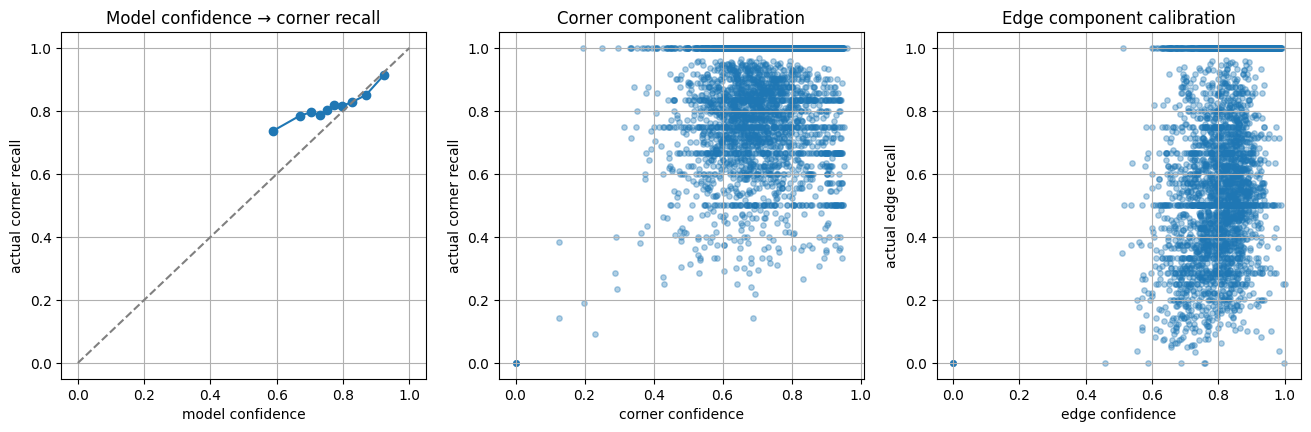

Saved figure: /kaggle/working/phase3_uncertainty/plots/05_confidence_calibration_components.png
Model confidence vs corner recall: 0.295
Corner confidence vs corner recall: 0.219
Edge confidence vs edge recall: 0.368
Hold-out isotonic calibration MAE: 0.134
Hold-out isotonic calibration RMSE: 0.163


In [10]:
print_section("1. CALIBRATION AGAINST HELD-OUT PHASE 2 TRUTH")

from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import train_test_split

results_df["confidence_bin"] = pd.qcut(
    results_df["model_confidence"].rank(method="first"),
    q=CONFIDENCE_BINS,
    labels=False,
) + 1

calibration_table = (
    results_df
    .groupby("confidence_bin", observed=False)
    .agg(
        model_confidence=("model_confidence", "mean"),
        corner_confidence=("corner_confidence", "mean"),
        edge_confidence=("edge_confidence", "mean"),
        actual_corner_recall=("actual_corner_recall", "mean"),
        actual_edge_recall=("actual_edge_recall", "mean"),
        n=("building_id", "size"),
    )
    .reset_index()
)

calibration_table.to_csv(OUT_DIR / "phase3_calibration_table.csv", index=False)
display(calibration_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(
    calibration_table["model_confidence"],
    calibration_table["actual_corner_recall"],
    marker="o",
)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("model confidence")
axes[0].set_ylabel("actual corner recall")
axes[0].set_title("Model confidence → corner recall")

axes[1].scatter(
    results_df["corner_confidence"],
    results_df["actual_corner_recall"],
    alpha=0.35,
    s=15,
)
axes[1].set_xlabel("corner confidence")
axes[1].set_ylabel("actual corner recall")
axes[1].set_title("Corner component calibration")

axes[2].scatter(
    results_df["edge_confidence"],
    results_df["actual_edge_recall"],
    alpha=0.35,
    s=15,
)
axes[2].set_xlabel("edge confidence")
axes[2].set_ylabel("actual edge recall")
axes[2].set_title("Edge component calibration")

save_show(fig, "05_confidence_calibration_components.png")

corr_model_corner = safe_corr(
    results_df, "model_confidence", "actual_corner_recall"
)
corr_corner = safe_corr(
    results_df, "corner_confidence", "actual_corner_recall"
)
corr_edge = safe_corr(
    results_df, "edge_confidence", "actual_edge_recall"
)

print(f"Model confidence vs corner recall: {corr_model_corner:.3f}")
print(f"Corner confidence vs corner recall: {corr_corner:.3f}")
print(f"Edge confidence vs edge recall: {corr_edge:.3f}")

calibration_input = results_df[
    ["model_confidence", "actual_corner_recall"]
].dropna().reset_index(drop=True)

if len(calibration_input) >= 20:
    rng = np.random.default_rng(42)
    indices = np.arange(len(calibration_input))
    rng.shuffle(indices)
    split = max(10, int(len(indices) * 0.70))
    fit_idx, eval_idx = indices[:split], indices[split:]

    iso = IsotonicRegression(
        y_min=0.0,
        y_max=1.0,
        out_of_bounds="clip",
    )
    iso.fit(
        calibration_input.loc[fit_idx, "model_confidence"],
        calibration_input.loc[fit_idx, "actual_corner_recall"],
    )

    calibrated = iso.predict(
        calibration_input.loc[eval_idx, "model_confidence"]
    )
    observed = calibration_input.loc[eval_idx, "actual_corner_recall"].to_numpy()
    calibration_mae = float(np.mean(np.abs(calibrated - observed)))
    calibration_rmse = float(np.sqrt(np.mean((calibrated - observed) ** 2)))

    print(f"Hold-out isotonic calibration MAE: {calibration_mae:.3f}")
    print(f"Hold-out isotonic calibration RMSE: {calibration_rmse:.3f}")

    pd.DataFrame({
        "model_confidence": calibration_input.loc[eval_idx, "model_confidence"].to_numpy(),
        "actual_corner_recall": observed,
        "calibrated_corner_recall": calibrated,
    }).to_csv(OUT_DIR / "phase3_isotonic_calibration_eval.csv", index=False)
else:
    calibration_mae = np.nan
    calibration_rmse = np.nan
    print("Not enough buildings for an isotonic calibration split.")


## 11. Dense vs. sparse coverage



2. DENSE VS SPARSE ANALYSIS


,n,corner_spread_m,edge_entropy,corner_confidence,edge_confidence,model_confidence,corner_recall,edge_recall,microsoft_iou
coverage_class,,,,,,,,,
dense,1633,0.059147,0.499002,0.715584,0.808018,0.761801,0.832975,0.661613,0.543301
sparse,1574,0.064445,0.560866,0.720214,0.810513,0.765363,0.793822,0.587959,0.581622


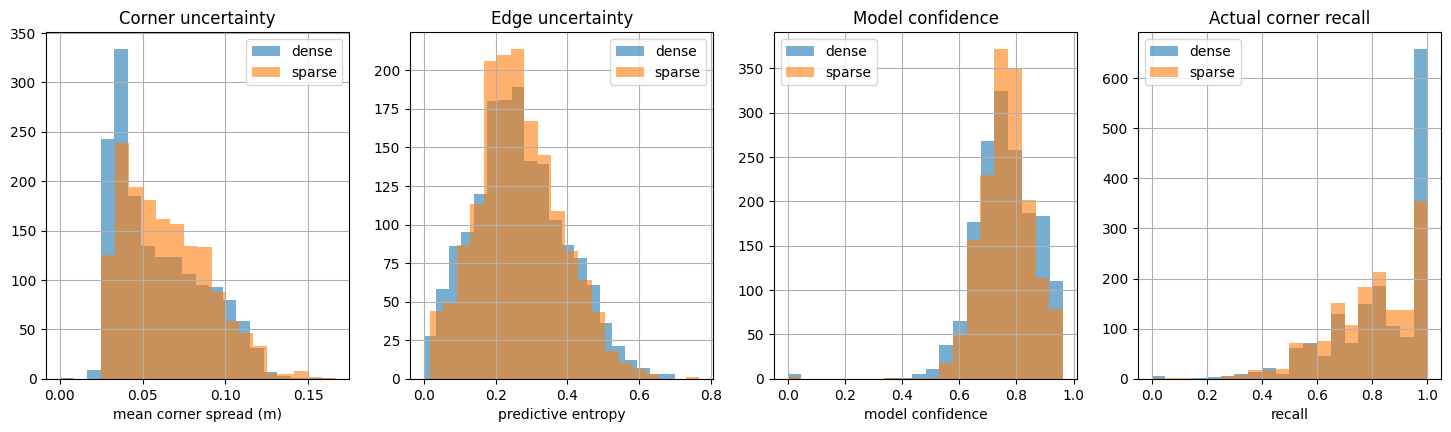

Saved figure: /kaggle/working/phase3_uncertainty/plots/02_dense_vs_sparse_uncertainty.png


In [11]:
print_section("2. DENSE VS SPARSE ANALYSIS")

grouped = (
    results_df
    .groupby("coverage_class", dropna=False)
    .agg(
        n=("building_id", "size"),
        corner_spread_m=("mean_corner_spread_m", "mean"),
        edge_entropy=("mean_edge_entropy", "mean"),
        corner_confidence=("corner_confidence", "mean"),
        edge_confidence=("edge_confidence", "mean"),
        model_confidence=("model_confidence", "mean"),
        corner_recall=("actual_corner_recall", "mean"),
        edge_recall=("actual_edge_recall", "mean"),
        microsoft_iou=("microsoft_iou", "mean"),
    )
)
display(grouped)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for cls in ["dense", "sparse"]:
    subset = results_df[results_df.coverage_class == cls]
    if len(subset) == 0:
        continue
    axes[0].hist(subset["mean_corner_spread_m"].dropna(), bins=20, alpha=0.6, label=cls)
    axes[1].hist(subset["edge_predictive_entropy"].dropna(), bins=20, alpha=0.6, label=cls)
    axes[2].hist(subset["model_confidence"].dropna(), bins=20, alpha=0.6, label=cls)
    axes[3].hist(subset["actual_corner_recall"].dropna(), bins=20, alpha=0.6, label=cls)

axes[0].set_title("Corner uncertainty")
axes[0].set_xlabel("mean corner spread (m)")
axes[1].set_title("Edge uncertainty")
axes[1].set_xlabel("predictive entropy")
axes[2].set_title("Model confidence")
axes[2].set_xlabel("model confidence")
axes[3].set_title("Actual corner recall")
axes[3].set_xlabel("recall")
for ax in axes:
    ax.legend()

save_show(fig, "02_dense_vs_sparse_uncertainty.png")



3. UNCERTAINTY DISTRIBUTIONS


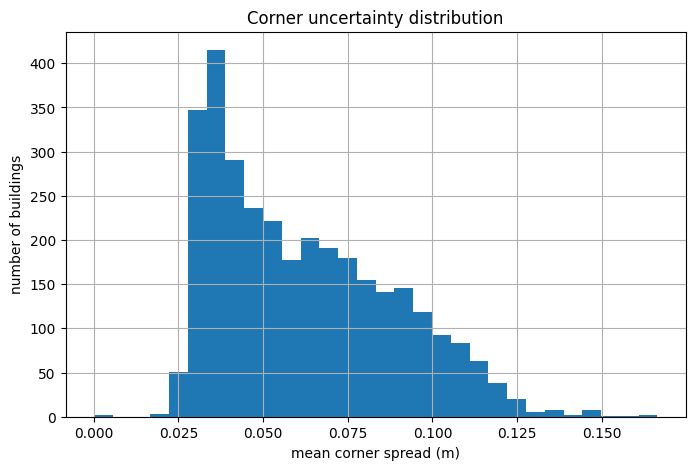

Saved figure: /kaggle/working/phase3_uncertainty/plots/03_corner_uncertainty_distribution.png


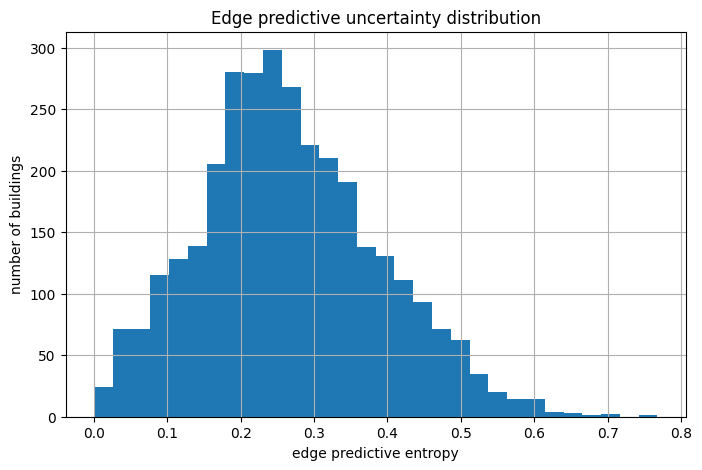

Saved figure: /kaggle/working/phase3_uncertainty/plots/04_edge_uncertainty_distribution.png


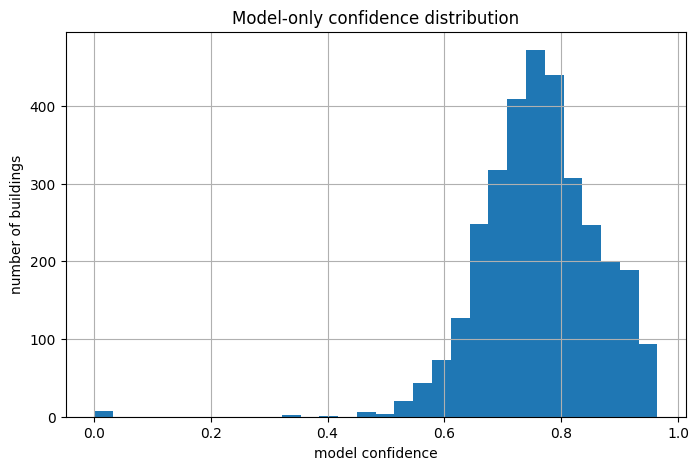

Saved figure: /kaggle/working/phase3_uncertainty/plots/01_confidence_distribution.png


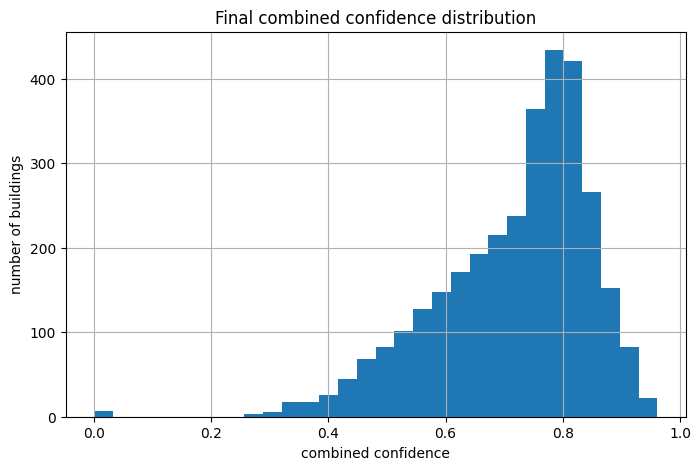

Saved figure: /kaggle/working/phase3_uncertainty/plots/01b_combined_confidence_distribution.png


In [12]:
print_section("3. UNCERTAINTY DISTRIBUTIONS")

fig, ax = plt.subplots()
ax.hist(results_df["mean_corner_spread_m"].dropna(), bins=30)
ax.set_xlabel("mean corner spread (m)")
ax.set_ylabel("number of buildings")
ax.set_title("Corner uncertainty distribution")
save_show(fig, "03_corner_uncertainty_distribution.png")

fig, ax = plt.subplots()
ax.hist(results_df["edge_predictive_entropy"].dropna(), bins=30)
ax.set_xlabel("edge predictive entropy")
ax.set_ylabel("number of buildings")
ax.set_title("Edge predictive uncertainty distribution")
save_show(fig, "04_edge_uncertainty_distribution.png")

fig, ax = plt.subplots()
ax.hist(results_df["model_confidence"].dropna(), bins=30)
ax.set_xlabel("model confidence")
ax.set_ylabel("number of buildings")
ax.set_title("Model-only confidence distribution")
save_show(fig, "01_confidence_distribution.png")

fig, ax = plt.subplots()
ax.hist(results_df["combined_confidence"].dropna(), bins=30)
ax.set_xlabel("combined confidence")
ax.set_ylabel("number of buildings")
ax.set_title("Final combined confidence distribution")
save_show(fig, "01b_combined_confidence_distribution.png")


## 12. External reference diagnostics



4. EXTERNAL REFERENCE ANALYSIS
OSM matched: 3193/3207
Microsoft matched: 2857/3207

OSM status counts:


,count
osm_status,
matched,3193
no_prediction,10
no_nearby_building,4



Microsoft status counts:


,count
microsoft_status,
matched,2857
no_nearby_building,336
no_prediction,10
no_partition_match,4


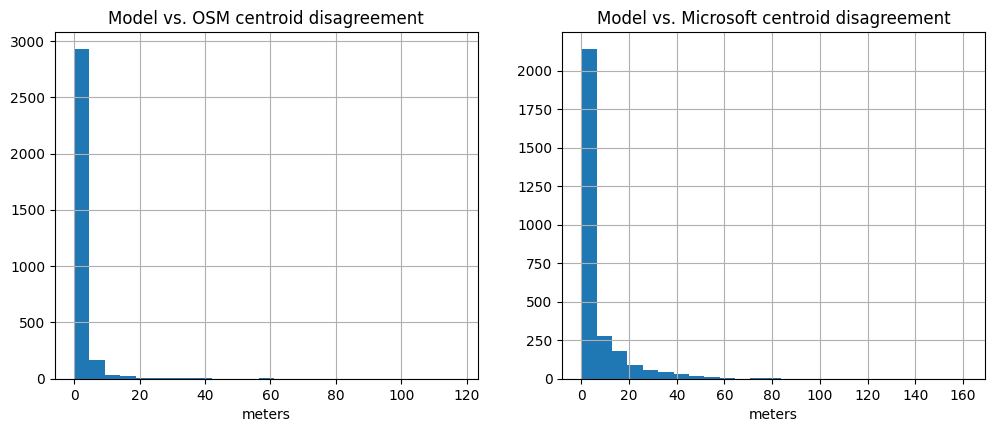

Saved figure: /kaggle/working/phase3_uncertainty/plots/06_07_external_disagreement_distributions.png


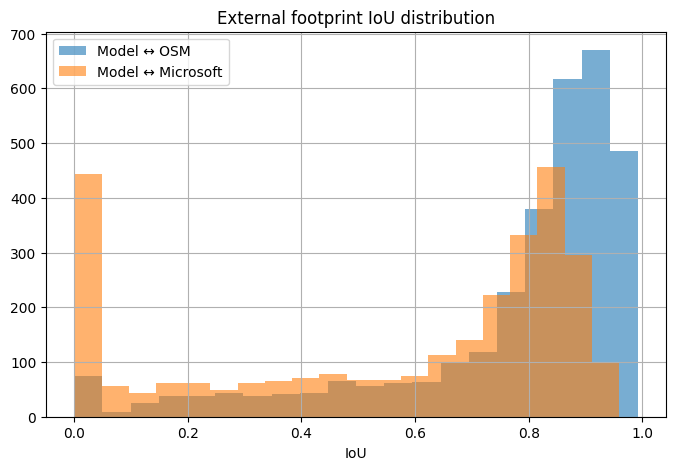

Saved figure: /kaggle/working/phase3_uncertainty/plots/08_iou_distribution.png


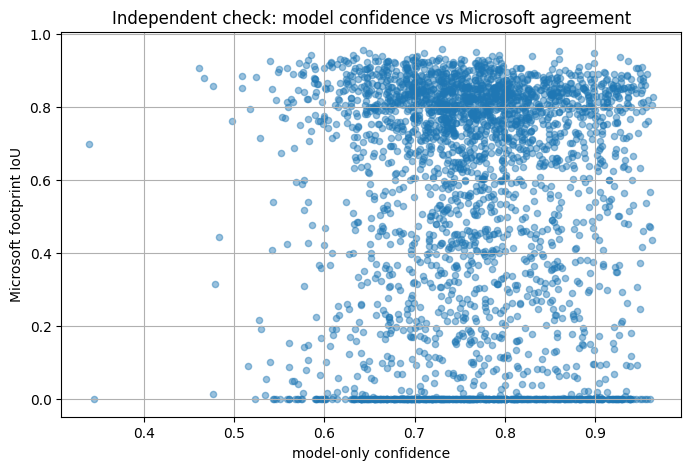

Saved figure: /kaggle/working/phase3_uncertainty/plots/09_model_confidence_vs_external_agreement.png
Model confidence vs Microsoft IoU correlation: -0.003
Model confidence vs OSM IoU correlation: 0.025

Important: combined confidence contains external agreement by construction.
Therefore model-confidence vs external-IoU is the independent validation statistic.


In [13]:
print_section("4. EXTERNAL REFERENCE ANALYSIS")

osm_avail = results_df[results_df.osm_available]
ms_avail = results_df[results_df.microsoft_available]

print(f"OSM matched: {len(osm_avail)}/{len(results_df)}")
print(f"Microsoft matched: {len(ms_avail)}/{len(results_df)}")

print("\nOSM status counts:")
display(results_df["osm_status"].value_counts(dropna=False).to_frame("count"))

print("\nMicrosoft status counts:")
display(results_df["microsoft_status"].value_counts(dropna=False).to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
if len(osm_avail):
    axes[0].hist(osm_avail["osm_centroid_distance_m"], bins=25)
axes[0].set_title("Model vs. OSM centroid disagreement")
axes[0].set_xlabel("meters")

if len(ms_avail):
    axes[1].hist(ms_avail["microsoft_centroid_distance_m"], bins=25)
axes[1].set_title("Model vs. Microsoft centroid disagreement")
axes[1].set_xlabel("meters")

save_show(fig, "06_07_external_disagreement_distributions.png")

fig, ax = plt.subplots()
if len(osm_avail):
    ax.hist(osm_avail["osm_iou"].dropna(), bins=20, alpha=0.6, label="Model ↔ OSM")
if len(ms_avail):
    ax.hist(ms_avail["microsoft_iou"].dropna(), bins=20, alpha=0.6, label="Model ↔ Microsoft")
ax.set_title("External footprint IoU distribution")
ax.set_xlabel("IoU")
ax.legend()
save_show(fig, "08_iou_distribution.png")

if len(ms_avail) >= 3:
    fig, ax = plt.subplots()
    ax.scatter(
        ms_avail["model_confidence"],
        ms_avail["microsoft_iou"],
        alpha=0.45,
        s=20,
    )
    ax.set_xlabel("model-only confidence")
    ax.set_ylabel("Microsoft footprint IoU")
    ax.set_title("Independent check: model confidence vs Microsoft agreement")
    save_show(fig, "09_model_confidence_vs_external_agreement.png")

    ms_corr = safe_corr(ms_avail, "model_confidence", "microsoft_iou")
    print(f"Model confidence vs Microsoft IoU correlation: {ms_corr:.3f}")
else:
    ms_corr = np.nan
    print("Not enough Microsoft matches for an external correlation.")

if len(osm_avail) >= 3:
    osm_corr = safe_corr(osm_avail, "model_confidence", "osm_iou")
    print(f"Model confidence vs OSM IoU correlation: {osm_corr:.3f}")
else:
    osm_corr = np.nan

print("\nImportant: combined confidence contains external agreement by construction.")
print("Therefore model-confidence vs external-IoU is the independent validation statistic.")


## 13. Building-level visual validation



5. BUILDING-LEVEL OVERLAY EXAMPLES


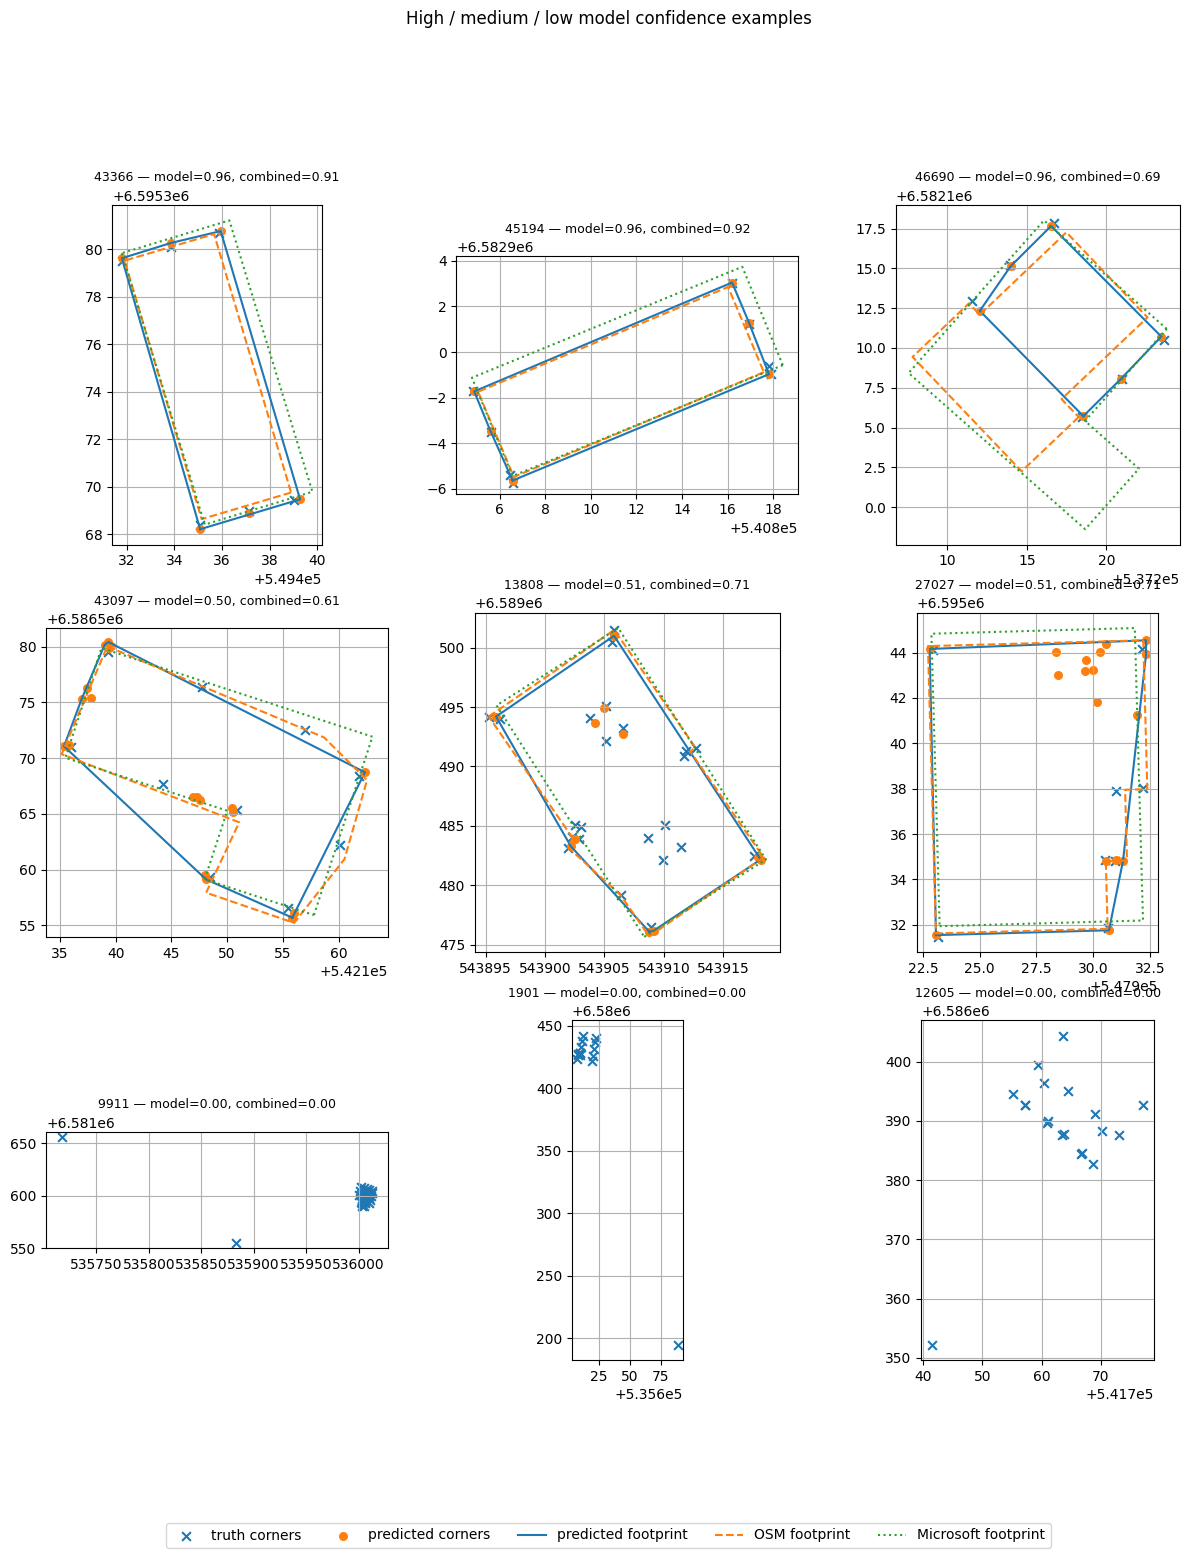

Saved figure: /kaggle/working/phase3_uncertainty/plots/10_building_level_overlay_examples.png


In [14]:
def plot_building_overlay(ax, building_id, row_data):
    item_row = index[index.building_id.astype(str) == str(building_id)].iloc[0]
    item = load_row(item_row)
    scale, center = float(item["scale"]), item["center"].numpy()
    n_corner = int(item["corner_count"])
    truth_m = denormalize(item["corners"][:n_corner].numpy(), center, scale)

    pts = item["points"].unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, offsets, shared = corner_model(pts)

    pred_norm, pred_scores = predict_corners(
        pts[0], logits[0], offsets[0], scale, score_thresh=SCORE_THRESH
    )
    pred_m = denormalize(pred_norm, center, scale)
    pred_poly = predicted_footprint_polygon(pred_m)

    ax.scatter(truth_m[:, 0], truth_m[:, 1], marker="x", s=40, label="truth corners")
    if len(pred_m):
        ax.scatter(pred_m[:, 0], pred_m[:, 1], s=30, label="predicted corners")

    if pred_poly is not None:
        px, py = pred_poly.exterior.xy
        ax.plot(px, py, linewidth=1.5, label="predicted footprint")

        centroid_xy = np.asarray(pred_poly.centroid.coords[0])

        if row_data.get("osm_available"):
            osm_poly, _ = fetch_osm_polygon(building_id, centroid_xy)
            if osm_poly is not None:
                ox, oy = osm_poly.exterior.xy
                ax.plot(ox, oy, linewidth=1.5, linestyle="--", label="OSM footprint")

        if row_data.get("microsoft_available"):
            ms_poly, _ = fetch_ms_polygon(building_id, centroid_xy)
            if ms_poly is not None:
                mx, my = ms_poly.exterior.xy
                ax.plot(mx, my, linewidth=1.5, linestyle=":", label="Microsoft footprint")

    ax.set_title(
        f"{building_id} — model={row_data['model_confidence']:.2f}, "
        f"combined={row_data['combined_confidence']:.2f}",
        fontsize=9,
    )
    ax.set_aspect("equal")


print_section("5. BUILDING-LEVEL OVERLAY EXAMPLES")

high = results_df.sort_values("model_confidence", ascending=False).head(3)
mid = results_df.iloc[
    (results_df["model_confidence"] - 0.5).abs().sort_values().index
].head(3)
low = results_df.sort_values("model_confidence", ascending=True).head(3)
examples = pd.concat([high, mid, low]).drop_duplicates("building_id")

fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for ax, (_, row_data) in zip(axes.flat, examples.iterrows()):
    try:
        plot_building_overlay(ax, row_data["building_id"], row_data)
    except Exception as error:
        ax.set_title(f"{row_data['building_id']} — plot failed: {error}", fontsize=8)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02))
fig.suptitle(
    "High / medium / low model confidence examples",
    y=1.01,
)
save_show(fig, "10_building_level_overlay_examples.png")



6. PER-BUILDING UNCERTAINTY: ALL PASSES


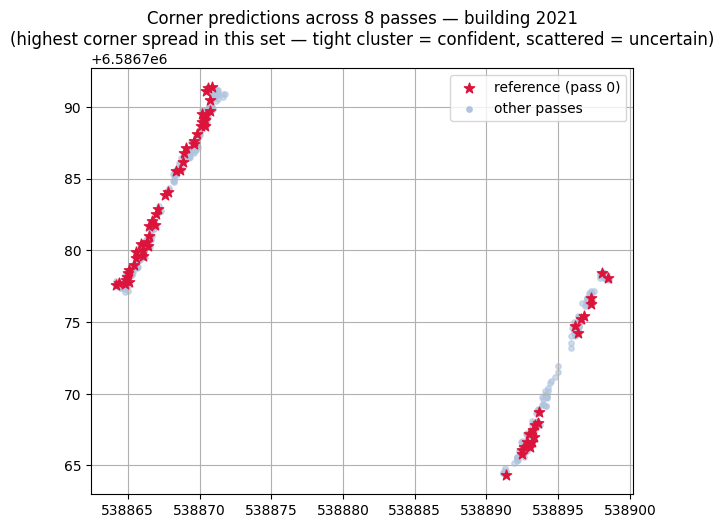

Saved figure: /kaggle/working/phase3_uncertainty/plots/11_corner_pass_cluster_example.png


In [15]:
print_section("6. PER-BUILDING UNCERTAINTY: ALL PASSES")

example_id = results_df.sort_values("mean_corner_spread_m", ascending=False).iloc[0]["building_id"]
example_row = index[index.building_id.astype(str) == example_id].iloc[0]
example_item = load_row(example_row)
rng = np.random.default_rng(0)
example_passes = multi_pass_corners(example_item, N_PASSES, JITTER_STD_M, DROP_FRACTION, SCORE_THRESH, rng)

fig, ax = plt.subplots(figsize=(7, 7))
for p in example_passes[1:]:
    if len(p["pred_m"]):
        ax.scatter(p["pred_m"][:, 0], p["pred_m"][:, 1], c="lightsteelblue", s=15, alpha=0.6)
ref = example_passes[0]["pred_m"]
if len(ref):
    ax.scatter(ref[:, 0], ref[:, 1], c="crimson", s=60, marker="*", label="reference (pass 0)", zorder=5)
ax.scatter([], [], c="lightsteelblue", s=15, label="other passes")
ax.set_aspect("equal")
ax.legend()
ax.set_title(f"Corner predictions across {N_PASSES} passes — building {example_id}\n(highest corner spread in this set — tight cluster = confident, scattered = uncertain)")
save_show(fig, "11_corner_pass_cluster_example.png")


## 14–15. Save results and numeric statistics


In [16]:
numeric_cols = results_df.select_dtypes(include=[np.number]).columns
numeric_stats = results_df[numeric_cols].describe().T
numeric_stats.to_csv(OUT_DIR / "phase3_numeric_statistics.csv")
display(numeric_stats)
print("\nWrote:", results_path)
print("Wrote:", OUT_DIR / "phase3_numeric_statistics.csv")


,count,mean,std,min,25%,50%,75%,max
num_points,3207.0,2048.000000,0.000000,2.048000e+03,2048.000000,2048.000000,2048.000000,2048.000000
num_predicted_corners,3207.0,15.086997,12.034012,0.000000e+00,6.000000,11.000000,21.000000,64.000000
num_predicted_edges,3207.0,27.112254,41.657126,0.000000e+00,6.000000,13.000000,31.500000,521.000000
n_ref_corners,3207.0,15.086997,12.034012,0.000000e+00,6.000000,11.000000,21.000000,64.000000
mean_corner_spread_m,3200.0,0.061750,0.026340,0.000000e+00,0.038438,0.056463,0.080442,0.166469
max_corner_spread_m,3200.0,0.126912,0.077559,0.000000e+00,0.053434,0.111403,0.189778,0.373236
mean_existence_rate,3200.0,0.811119,0.128293,1.250000e-01,0.733333,0.818182,0.901786,1.000000
corner_confidence,3207.0,0.717856,0.134346,0.000000e+00,0.633394,0.714884,0.816192,0.960526
mean_edge_entropy,3200.0,0.529392,0.211802,1.284973e-04,0.387455,0.570954,0.694831,0.947484
edge_predictive_entropy,3200.0,0.266460,0.121774,1.284973e-04,0.183581,0.255496,0.345182,0.767862



Wrote: /kaggle/working/phase3_uncertainty/phase3_results.csv
Wrote: /kaggle/working/phase3_uncertainty/phase3_numeric_statistics.csv


## 16. Final summary


In [17]:
summary = {
    "n_passes": int(N_PASSES),
    "score_thresh": float(SCORE_THRESH),
    "match_tolerance_m": float(MATCH_TOLERANCE_M),
    "n_buildings_scored": int(len(results_df)),
    "confidence_class_counts": results_df["confidence_class"].value_counts().to_dict(),
    "osm_available_rate": float(results_df["osm_available"].mean()),
    "microsoft_available_rate": float(results_df["microsoft_available"].mean()),
    "osm_status_counts": results_df["osm_status"].value_counts(dropna=False).to_dict(),
    "microsoft_status_counts": results_df["microsoft_status"].value_counts(dropna=False).to_dict(),
    "model_confidence_vs_corner_recall_correlation": corr_model_corner,
    "corner_confidence_vs_corner_recall_correlation": corr_corner,
    "edge_confidence_vs_edge_recall_correlation": corr_edge,
    "model_confidence_vs_microsoft_iou_correlation": ms_corr,
    "model_confidence_vs_osm_iou_correlation": osm_corr,
    "isotonic_holdout_mae": calibration_mae,
    "isotonic_holdout_rmse": calibration_rmse,
    "mean_confidence_by_coverage_class": results_df.groupby("coverage_class")["model_confidence"].mean().to_dict(),
    "mean_corner_recall_by_coverage_class": results_df.groupby("coverage_class")["actual_corner_recall"].mean().to_dict(),
    "mean_edge_recall_by_coverage_class": results_df.groupby("coverage_class")["actual_edge_recall"].mean().to_dict(),
    "mean_osm_iou": float(results_df["osm_iou"].mean(skipna=True)) if results_df["osm_available"].any() else None,
    "mean_microsoft_iou": float(results_df["microsoft_iou"].mean(skipna=True)) if results_df["microsoft_available"].any() else None,
    "osm_reference_status": _osm_status,
}

with open(OUT_DIR / "phase3_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else x)

print_section("PHASE 3 SUMMARY")
summary_display = {
    k: v for k, v in summary.items()
    if not isinstance(v, (dict, list))
}
display(pd.Series(summary_display).to_frame("value"))

print("\nWrote:", results_path)
print("Wrote:", OUT_DIR / "phase3_summary.json")
print("Plots:", PLOTS_DIR)
print("Calibration table:", OUT_DIR / "phase3_calibration_table.csv")



PHASE 3 SUMMARY


,value
n_passes,8.000000
score_thresh,0.700000
match_tolerance_m,1.000000
n_buildings_scored,3207.000000
osm_available_rate,0.995635
microsoft_available_rate,0.890864
model_confidence_vs_corner_recall_correlation,0.295243
corner_confidence_vs_corner_recall_correlation,0.218720
edge_confidence_vs_edge_recall_correlation,0.368113
model_confidence_vs_microsoft_iou_correlation,-0.002685



Wrote: /kaggle/working/phase3_uncertainty/phase3_results.csv
Wrote: /kaggle/working/phase3_uncertainty/phase3_summary.json
Plots: /kaggle/working/phase3_uncertainty/plots
Calibration table: /kaggle/working/phase3_uncertainty/phase3_calibration_table.csv


## Final interpretation and next phase

- **OSM:** use the explicit status counts to distinguish API failure from genuine absence of a nearby building.
- **Microsoft:** matching uses a spatial index per tile, so the same tile is parsed once and candidate polygons are queried spatially.
- **Model confidence:** calibration is evaluated against held-out Phase 2 corner/edge truth.
- **External validation:** the independent statistic is **model-only confidence vs external IoU**. Do not interpret `combined_confidence vs external IoU` as independent validation because external agreement is part of the combined score.
- **Dense vs sparse:** report uncertainty and held-out reconstruction metrics by coverage class.
- **Confidence bands:** `high`, `medium`, and `low` describe estimated reliability under this formulation. They are not correctness labels.
- **Footprint limitation:** the predicted footprint is a convex hull of predicted corners, so concave buildings require cautious IoU interpretation.
- **ETAK:** keep it documented as a future authoritative Estonian reference rather than silently treating it as available in this experiment.
